# CSE 438 - Assignment 01
## Group Information
| Field | Details |
|----------------------------|----------------------------------------------|
| **Group ID** | Group B |
| **Student 1 Name** | Nasrullah Kaisher Sijan |
| **Student 1 ID** | 2023-1-60-204 |
| **Student 2 Name** | G M MOTA-TAHRIN TAYEF |
| **Student 2 ID** | 2022-1-60-109 |
| **Student 3 Name** | Bushra Tahsin |
| **Student 3 ID** | 2023-3-60-129 |
| **Notebook Type** | Segformer Notebook |
| **Assignment 01 Best Acc** | Semantic Segmentation Model Benchmark-ing |
| **Dataset Name (Kaggle)** | /kaggle/input/datasets/nasrullahsijan/kvasir-capsule-endoscopy/Kvasir capsule endoscopy dataset |
| **Dataset Source** | Pixel-wise Annotation for Clear and Contaminated Regions Segmentation in Wireless Capsule Endoscopy Images: Kvasir capsule endoscopy |
| **Dataset Source Link** | https://data.mendeley.com/datasets/vmxhn95j8z/3 |
| **Submission Date** | 14 July 2026 |

# SegFormer-B0 — Part 2 (Post-Training Continuation)

## Purpose of this notebook

Training for SegFormer-B0 (MiT-B0 backbone, binary Clear/Contaminated
segmentation on the Kvasir Capsule Endoscopy dataset) **already completed
successfully** in the original training notebook. That notebook crashed
*after* training finished, but every checkpoint, log, figure, and report it
produced up to that point is intact on disk.

**This notebook never trains.** There is no `for epoch in ...` loop, no
`trainer.train()`, no `loss.backward()`, no `optimizer.step()` used for
training, and no scheduler stepping. It only:

1. Locates the previous run's output directory.
2. Copies every previous artifact into a **new**, separate output directory
   (so nothing from the completed experiment is ever overwritten).
3. Rebuilds the exact same SegFormer-B0 model/preprocessing pipeline used
   during training.
4. Loads `best_model.pth` for **inference and evaluation only**.
5. Runs every remaining post-training task: test-set evaluation, error
   analysis, qualitative visualizations, metrics export, and reporting —
   writing all new outputs into the new directory.

This notebook is fully standalone: if only `SegFormer_Part2.ipynb` is
opened (the original training notebook is not required), and the previous
output directory and Notebook 0 preprocessing artifacts exist on disk, it
will run end-to-end.


---
# Section 1 — Import Libraries


In [1]:
# ============================================================================
# IMPORTS
# ============================================================================
import json
import platform
import random
import shutil
import time
import warnings
from datetime import datetime
from pathlib import Path
from typing import Any, Optional, Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tqdm.auto import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor
import transformers

import cv2
cv2.setNumThreads(0)  # avoid fighting with DataLoader's own worker processes

from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})

print("Imports complete.")
print(f"  torch version          : {torch.__version__}")
print(f"  torchvision version    : {torchvision.__version__}")
print(f"  transformers version   : {transformers.__version__}")
print(f"  albumentations version : {A.__version__}")


Imports complete.
  torch version          : 2.10.0+cu128
  torchvision version    : 0.25.0+cu128
  transformers version   : 5.0.0
  albumentations version : 2.0.8


---
# Section 2 — Locate Previous Output Directory

This notebook never re-derives, re-splits, or recomputes anything Notebook
0 or the original training notebook already produced. `PREVIOUS_OUTPUT_ROOT`
below is searched for the completed run's `results/segformer/` tree
(specifically, `results/segformer/checkpoints/best_model.pth`, which is the
one artifact that must exist for this notebook to proceed). A short list of
likely candidate locations is checked automatically (the current working
directory, common Kaggle input mount points, etc.) so this cell usually
needs no editing — but the path can be set explicitly if none of the
candidates match.


In [2]:
# ============================================================================
# CONFIGURATION -- locate the completed training run's output directory
# ============================================================================

# Set this explicitly if none of the auto-detected candidates below are
# correct for your environment. Left as None to trigger auto-detection.
PREVIOUS_OUTPUT_ROOT_OVERRIDE: Optional[str] = None

_RELATIVE_MARKER = Path("results") / "segformer" / "checkpoints" / "best_model.pth"

_candidate_roots = [
    Path("/kaggle/input/datasets/bushratahsin/segformer-result2"),
    Path("/kaggle/input/datasets/bushratahsin/segformer-result2/results/segformer"),
    Path("/kaggle/working/segformer-result2"),
    Path("/kaggle/input/datasets/bushratahsin/segformer-result2/results"),
]
# Also sweep one level of /kaggle/input for any dataset containing the marker.
if Path("/kaggle/input").is_dir():
    _candidate_roots.extend(sorted(p for p in Path("/kaggle/input").glob("*") if p.is_dir()))
    _candidate_roots.extend(sorted(p for p in Path("/kaggle/input").glob("*/*") if p.is_dir()))


class PreviousOutputNotFoundError(RuntimeError):
    """Raised when the completed training run's output directory cannot be
    located automatically and no explicit override was provided.
    """


def locate_previous_output_root(
    candidates: list, marker: Path, override: Optional[str] = None
) -> Path:
    if override is not None:
        root = Path(override)
        if (root / marker).is_file():
            return root
        raise PreviousOutputNotFoundError(
            f"PREVIOUS_OUTPUT_ROOT_OVERRIDE={override!r} does not contain {marker}."
        )
    seen = set()
    for root in candidates:
        root = Path(root)
        if root in seen:
            continue
        seen.add(root)
        if (root / marker).is_file():
            return root
    raise PreviousOutputNotFoundError(
        f"Could not find '{marker}' under any candidate root: "
        f"{[str(c) for c in candidates]}. Set PREVIOUS_OUTPUT_ROOT_OVERRIDE above "
        f"to the directory containing your completed 'results/segformer/' tree."
    )


PREVIOUS_OUTPUT_ROOT = locate_previous_output_root(
    _candidate_roots, _RELATIVE_MARKER, PREVIOUS_OUTPUT_ROOT_OVERRIDE
).resolve()
PREVIOUS_RESULTS_DIR = PREVIOUS_OUTPUT_ROOT / "results" / "segformer"
PREVIOUS_CHECKPOINTS_DIR = PREVIOUS_RESULTS_DIR / "checkpoints"

print(f"Previous output root found : {PREVIOUS_OUTPUT_ROOT}")
print(f"Previous results directory  : {PREVIOUS_RESULTS_DIR}")
assert (PREVIOUS_CHECKPOINTS_DIR / "best_model.pth").is_file(), "best_model.pth missing -- cannot proceed."
print(f"\nConfirmed: {PREVIOUS_CHECKPOINTS_DIR / 'best_model.pth'} exists.")

print("\nContents of the previous output directory:")
for p in sorted(PREVIOUS_OUTPUT_ROOT.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(PREVIOUS_OUTPUT_ROOT)}")


Previous output root found : /kaggle/input/datasets/bushratahsin/segformer-result2
Previous results directory  : /kaggle/input/datasets/bushratahsin/segformer-result2/results/segformer

Confirmed: /kaggle/input/datasets/bushratahsin/segformer-result2/results/segformer/checkpoints/best_model.pth exists.

Contents of the previous output directory:
  __huggingface_repos__.json
  __results___files/__results___14_0.png
  __results___files/__results___40_0.png
  __results___files/__results___40_1.png
  __results___files/__results___40_2.png
  __results___files/__results___40_3.png
  __results___files/__results___40_4.png
  results/segformer/checkpoints/best_model.pth
  results/segformer/checkpoints/best_model_epoch001_miou0.8428.pth
  results/segformer/checkpoints/best_model_epoch002_miou0.8634.pth
  results/segformer/checkpoints/best_model_epoch004_miou0.8679.pth
  results/segformer/checkpoints/best_model_epoch005_miou0.8803.pth
  results/segformer/checkpoints/best_model_epoch007_miou0.8878

---
# Section 3 — Create New Output Directory

Per the task requirements, this notebook **never writes into, or
overwrites anything inside,** `PREVIOUS_OUTPUT_ROOT`. A brand-new sibling
directory is created instead, and every new artifact this notebook
produces (from this point forward) is written there.


In [3]:
# ============================================================================
# NEW OUTPUT DIRECTORY -- this notebook's own outputs never touch the
# previous run's directory
# ============================================================================
NEW_OUTPUT_ROOT = Path("segformer-result2-part2")
NEW_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print(f"New output directory : {NEW_OUTPUT_ROOT.resolve()}")


New output directory : /kaggle/working/segformer-result2-part2


---
# Section 4 — Copy Previous Outputs

Every file under `PREVIOUS_OUTPUT_ROOT` (checkpoints, config, figures,
logs, reports, `__results___files/`, `__huggingface_repos__.json`, etc.) is
copied into `NEW_OUTPUT_ROOT` before anything new is written, so nothing
from the completed experiment is ever lost. Copying is skipped for any
file that already exists identically in the destination, so this cell is
safe to re-run.


In [4]:
# ============================================================================
# COPY EVERYTHING FROM THE PREVIOUS OUTPUT DIRECTORY INTO THE NEW ONE
# ============================================================================
def copy_tree_preserving(src: Path, dst: Path) -> tuple[int, int]:
    """Copy every file under `src` into `dst`, preserving the relative
    directory structure. Returns (n_copied, n_skipped_existing).
    """
    n_copied, n_skipped = 0, 0
    for src_path in src.rglob("*"):
        if src_path.is_dir():
            continue
        rel_path = src_path.relative_to(src)
        dst_path = dst / rel_path
        dst_path.parent.mkdir(parents=True, exist_ok=True)
        if dst_path.is_file() and dst_path.stat().st_size == src_path.stat().st_size:
            n_skipped += 1
            continue
        shutil.copy2(src_path, dst_path)
        n_copied += 1
    return n_copied, n_skipped


n_copied, n_skipped = copy_tree_preserving(PREVIOUS_OUTPUT_ROOT, NEW_OUTPUT_ROOT)
print(f"Copied {n_copied} file(s) from {PREVIOUS_OUTPUT_ROOT} -> {NEW_OUTPUT_ROOT}")
print(f"Skipped {n_skipped} file(s) already present and identical in size.")

# This notebook's OWN new outputs (from this point on) are written under the
# same 'results/segformer/' sub-tree inside the NEW root, so every later
# section's relative paths (FIGURES_DIR, TABLES_DIR, etc.) stay identical in
# *shape* to the original notebook -- only the root has moved.
OUTPUT_DIR = NEW_OUTPUT_ROOT / "results" / "segformer"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CONFIG_DIR = OUTPUT_DIR / "config"
FIGURES_DIR = OUTPUT_DIR / "figures"
LOGS_DIR = OUTPUT_DIR / "logs"
REPORTS_DIR = OUTPUT_DIR / "reports"
TABLES_DIR = OUTPUT_DIR / "tables"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
for directory in (OUTPUT_DIR, CHECKPOINT_DIR, CONFIG_DIR, FIGURES_DIR, LOGS_DIR, REPORTS_DIR, TABLES_DIR, PREDICTIONS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"\nAll new outputs from this notebook will be written under: {OUTPUT_DIR.resolve()}")


Copied 32 file(s) from /kaggle/input/datasets/bushratahsin/segformer-result2 -> segformer-result2-part2
Skipped 0 file(s) already present and identical in size.

All new outputs from this notebook will be written under: /kaggle/working/segformer-result2-part2/results/segformer


---
# Section 5 — Load Preprocessing Outputs & Training Configuration

Reusing the previous run's exported `training_configuration.json` (copied
into the new directory in Section 4) guarantees the model, preprocessing,
and label mapping reconstructed below are **exactly** what training used —
nothing here is guessed or re-derived. Notebook 0's preprocessing
artifacts (`train.csv` / `validation.csv` / `test.csv`,
`augmentation_config.json`, `label_mapping.json`) are loaded the same way
the original notebook loaded them, since they live outside
`results/segformer/` and were never copied by Section 4.


In [5]:
# ============================================================================
# LOAD THE PREVIOUS RUN'S TRAINING CONFIGURATION (authoritative)
# ============================================================================
TRAINING_CONFIG_PATH = CONFIG_DIR / "training_configuration.json"
if not TRAINING_CONFIG_PATH.is_file():
    raise FileNotFoundError(
        f"{TRAINING_CONFIG_PATH} not found -- Section 4 should have copied it "
        f"from the previous run. Cannot reconstruct the model without it."
    )
with open(TRAINING_CONFIG_PATH) as f:
    TRAINING_CONFIG = json.load(f)

print("Loaded training_configuration.json from the completed run:")
for key, value in TRAINING_CONFIG.items():
    print(f"  {key:<28}: {value}")

SEGFORMER_CHECKPOINT: str = TRAINING_CONFIG["pretrained_weights"]
NUM_CLASSES: int = TRAINING_CONFIG["num_classes"]
IMAGE_SIZE: tuple = tuple(TRAINING_CONFIG["input_image_size"])
CLASS_NAMES_BY_INDEX: list = TRAINING_CONFIG["class_names_by_index"]
BATCH_SIZE: int = TRAINING_CONFIG["batch_size"]
RANDOM_SEED: int = TRAINING_CONFIG["random_seed"]


Loaded training_configuration.json from the completed run:
  model_name                  : SegFormer-B0
  backbone                    : MiT-B0 (Mix Transformer)
  pretrained_weights          : nvidia/segformer-b0-finetuned-ade-512-512
  num_classes                 : 2
  input_image_size            : [336, 336]
  batch_size                  : 16
  epochs                      : 60
  optimizer                   : AdamW
  initial_learning_rate       : 6e-05
  lr_scheduler                : PolynomialLR
  lr_scheduler_params         : {'total_iters': 60, 'power': 1.0}
  loss_function               : weighted_ce_dice
  loss_function_params        : {'ce_weight': 0.5, 'dice_weight': 0.5}
  class_weights               : [0.11037527769804001, 1.889624834060669]
  class_names_by_index        : ['Clear', 'Contaminated']
  weight_decay                : 0.01
  mixed_precision             : True
  gradient_clipping_max_norm  : 1.0
  early_stopping_patience     : 10
  early_stopping_monitor      : val

In [6]:
# ============================================================================
# CONFIGURATION -- Notebook 0's preprocessing artifacts (unchanged from the
# original notebook; this is the only path here that may need editing)
# ============================================================================
PREPROCESSING_ROOT = Path("/kaggle/input/datasets/bushratahsin/result6/results")

TRAIN_CSV_PATH = PREPROCESSING_ROOT / "splits" / "train.csv"
VALIDATION_CSV_PATH = PREPROCESSING_ROOT / "splits" / "validation.csv"
TEST_CSV_PATH = PREPROCESSING_ROOT / "splits" / "test.csv"
AUGMENTATION_CONFIG_PATH = PREPROCESSING_ROOT / "augmentation" / "augmentation_config.json"
PREPROCESSING_METADATA_PATH = PREPROCESSING_ROOT / "metadata" / "preprocessing_metadata.json"
LABEL_MAPPING_PATH = PREPROCESSING_ROOT / "metadata" / "label_mapping.json"

required_files: dict[str, Path] = {
    "train.csv": TRAIN_CSV_PATH,
    "validation.csv": VALIDATION_CSV_PATH,
    "test.csv": TEST_CSV_PATH,
    "augmentation_config.json": AUGMENTATION_CONFIG_PATH,
    "preprocessing_metadata.json": PREPROCESSING_METADATA_PATH,
    "label_mapping.json": LABEL_MAPPING_PATH,
}
_missing = [name for name, path in required_files.items() if not path.is_file()]
if _missing:
    raise FileNotFoundError(
        f"The following required Notebook 0 artifacts are missing under "
        f"'{PREPROCESSING_ROOT.resolve()}': {_missing}. Correct PREPROCESSING_ROOT above."
    )

with open(PREPROCESSING_METADATA_PATH) as f:
    preprocessing_metadata = json.load(f)
with open(LABEL_MAPPING_PATH) as f:
    label_mapping = json.load(f)
with open(AUGMENTATION_CONFIG_PATH) as f:
    augmentation_config = json.load(f)

train_df = pd.read_csv(TRAIN_CSV_PATH)
validation_df_split = pd.read_csv(VALIDATION_CSV_PATH)
test_df = pd.read_csv(TEST_CSV_PATH)

print(f"Loaded preprocessing artifacts from {PREPROCESSING_ROOT}")
print(f"  Training samples   : {len(train_df)}")
print(f"  Validation samples : {len(validation_df_split)}")
print(f"  Test samples       : {len(test_df)}")


Loaded preprocessing artifacts from /kaggle/input/datasets/bushratahsin/result6/results
  Training samples   : 10526
  Validation samples : 2206
  Test samples       : 2411


---
# Section 6 — Rebuild SegFormer Model, Transforms & Dataset

Every helper below (dataset class, transform reconstruction, class-index
convention, model builder) is reused **verbatim** from the original
training notebook, so the data this notebook evaluates on is guaranteed
pixel-for-pixel identical to what training used. No training-only pieces
(loss function, optimizer, scheduler, `EarlyStopping`, checkpoint *saving*)
are reproduced here -- only what inference and evaluation require.


In [7]:
# ============================================================================
# FIXED TRAINING CLASS CONVENTION (verbatim from the original notebook)
# ============================================================================
FIXED_CLASS_MAPPING: dict[str, int] = {"Background": 0, "Clear": 0, "Contaminated": 1}
VALID_CLASS_INDICES = set(FIXED_CLASS_MAPPING.values())


class InvalidMaskError(ValueError):
    """Raised when a binary mask decodes to a pixel value outside {0, 1}."""


def load_image(path: Union[str, Path]) -> np.ndarray:
    """Load an image as an RGB uint8 array (OpenCV loads BGR by default)."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image at {path} (missing or corrupted).")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def load_binary_mask(path: Union[str, Path]) -> np.ndarray:
    """Load a Binary GT mask as a single-channel grayscale array (raw pixel
    values, not yet remapped to class indices).
    """
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(f"Could not read mask at {path} (missing or corrupted).")
    return mask


def mask_to_class_indices(raw_mask: np.ndarray, label_mapping: dict) -> np.ndarray:
    """Convert a raw grayscale mask into the fixed training convention
    (Clear=0, Contaminated=1), resolving the raw-pixel-value -> class-name
    mapping from Notebook 0's auto-detected `label_mapping.json`.
    """
    white_key = label_mapping["white_pixel_label"]
    black_key = "0" if white_key == "1" else "1"
    is_white = raw_mask >= 128
    class_indices = np.where(
        is_white, FIXED_CLASS_MAPPING[label_mapping[white_key]], FIXED_CLASS_MAPPING[label_mapping[black_key]]
    ).astype(np.int64)

    unique_values = set(np.unique(class_indices).tolist())
    if not unique_values.issubset(VALID_CLASS_INDICES):
        raise InvalidMaskError(f"Mask decoded to invalid class indices {unique_values - VALID_CLASS_INDICES}.")
    return class_indices


def overlay_mask(image: np.ndarray, class_mask: np.ndarray, alpha: float = 0.4) -> np.ndarray:
    """Tint contaminated pixels (class 1) red for visual inspection."""
    is_contaminated = (class_mask == FIXED_CLASS_MAPPING["Contaminated"])
    tint = np.zeros_like(image); tint[..., 0] = 255
    return np.where(is_contaminated[..., None], (image * (1 - alpha) + tint * alpha).astype(np.uint8), image)


print(f"Fixed training class convention: {FIXED_CLASS_MAPPING}")


Fixed training class convention: {'Background': 0, 'Clear': 0, 'Contaminated': 1}


In [8]:
# ============================================================================
# TRANSFORM PIPELINE -- reconstructed from augmentation_config.json
# (verbatim from the original notebook; only 'eval_pipeline' is needed here)
# ============================================================================
class AugmentationConfigError(RuntimeError):
    """Raised when augmentation_config.json cannot be used to reconstruct
    an Albumentations pipeline.
    """


def build_transform_from_config(config: dict, pipeline_key: str) -> A.Compose:
    """Reconstruct an Albumentations pipeline directly from the loaded
    augmentation_config.json dict.
    """
    try:
        steps = []
        for step in sorted(config[pipeline_key], key=lambda s: s["order"]):
            transform_cls = getattr(A, step["name"], None) or (ToTensorV2 if step["name"] == "ToTensorV2" else None)
            if transform_cls is None:
                raise KeyError(f"Unknown transform '{step['name']}'")
            params = dict(step["parameters"])
            if step["probability"] is not None:
                params["p"] = step["probability"]
            steps.append(transform_cls(**params))
        return A.Compose(steps)
    except (KeyError, TypeError, ValueError) as exc:
        raise AugmentationConfigError(
            f"Could not reconstruct the '{pipeline_key}' pipeline from "
            f"{AUGMENTATION_CONFIG_PATH}: {exc}"
        ) from exc


eval_transform = build_transform_from_config(augmentation_config, "eval_pipeline")

_normalization = augmentation_config.get("normalization", {})
NORMALIZATION_MEAN: tuple = tuple(_normalization.get("mean", (0.485, 0.456, 0.406)))
NORMALIZATION_STD: tuple = tuple(_normalization.get("std", (0.229, 0.224, 0.225)))

print(f"eval_transform reconstructed with {len(eval_transform.transforms)} step(s).")


eval_transform reconstructed with 2 step(s).


In [9]:
# ============================================================================
# DATASET CLASS (verbatim from the original notebook)
# ============================================================================
class KvasirSegmentationDataset(Dataset):
    """Self-contained PyTorch Dataset reading exclusively from a Notebook 0
    split CSV (train.csv / validation.csv / test.csv) -- never scans a
    folder, never recreates a split.
    """

    def __init__(self, csv_path: Union[str, Path], transform: A.Compose, label_mapping: dict) -> None:
        self.csv_path = Path(csv_path)
        if not self.csv_path.is_file():
            raise FileNotFoundError(f"Split CSV not found: {self.csv_path}")
        self.dataframe = pd.read_csv(self.csv_path)
        self.transform = transform
        self.label_mapping = label_mapping

    def __len__(self) -> int:
        return len(self.dataframe)

    def __getitem__(self, index: int) -> dict[str, Any]:
        row = self.dataframe.iloc[index]
        image = load_image(row["image_path"])
        raw_mask = load_binary_mask(row["binary_mask_path"])
        class_mask = mask_to_class_indices(raw_mask, self.label_mapping)

        transformed = self.transform(image=image, mask=class_mask)
        mask_out = transformed["mask"]

        return {
            "image": transformed["image"],
            "mask": mask_out.long() if torch.is_tensor(mask_out) else torch.from_numpy(mask_out).long(),
            "image_filename": row["image_filename"],
            "contaminated_percent": float(row["contaminated_percent"]),
            "cleanliness_label": str(row["cleanliness_label"]),
        }


def set_global_seed(seed: int) -> None:
    """Seed Python's `random`, NumPy, and PyTorch (CPU and CUDA)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_global_seed(RANDOM_SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Reproducibility configured: RANDOM_SEED={RANDOM_SEED}")
print(f"Device: {DEVICE}")


Reproducibility configured: RANDOM_SEED=42
Device: cuda


In [10]:
# ============================================================================
# BUILD SEGFORMER-B0 (verbatim from the original notebook)
# ============================================================================
def build_segformer_model(num_classes: int, checkpoint: str = SEGFORMER_CHECKPOINT) -> nn.Module:
    """Construct a SegFormer-B0 model from a HuggingFace checkpoint, with its
    classification head replaced to output `num_classes` channels.

    Important: the returned model's `forward()` returns a HuggingFace
    `SemanticSegmenterOutput` object (not a dict and not a raw tensor), and
    its `.logits` are at 1/4 of the input resolution -- any inference code
    must both index `output.logits` and bilinearly upsample it back to
    `IMAGE_SIZE` before computing a pixel-aligned metric (see `extract_logits`
    in Section 8).
    """
    model = SegformerForSemanticSegmentation.from_pretrained(
        checkpoint, num_labels=num_classes, ignore_mismatched_sizes=True,
    )
    return model


def summarize_model(model: nn.Module, model_name: str = "model") -> dict[str, Any]:
    """Report trainable/total parameter counts, estimated size, and device
    for any PyTorch model.
    """
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    size_mb = sum(p.numel() * p.element_size() for p in model.parameters()) / (1024 ** 2)
    device = next(model.parameters()).device
    summary = {
        "model_name": model_name, "total_parameters": total_params,
        "trainable_parameters": trainable_params, "estimated_size_mb": size_mb, "device": str(device),
    }
    print(f"Model summary -- {model_name}:")
    print(f"  Total parameters      : {total_params:,}")
    print(f"  Trainable parameters   : {trainable_params:,}")
    print(f"  Estimated size           : {size_mb:.2f} MB")
    print(f"  Device                     : {device}")
    return summary


print(f"build_segformer_model ready (checkpoint='{SEGFORMER_CHECKPOINT}', num_classes={NUM_CLASSES}).")


build_segformer_model ready (checkpoint='nvidia/segformer-b0-finetuned-ade-512-512', num_classes=2).


---
# Section 7 — Rebuild Model & Load Best Checkpoint

The checkpoint is loaded **only** for inference and evaluation. Model
weights are restored via `load_state_dict`; optimizer/scheduler state,
epoch number, best validation mIoU, and any stored config/metadata are
also read back from the checkpoint (and reconstructed where needed) purely
for reporting and consistency-checking -- they are **never** used to
resume a training loop, since no training loop exists in this notebook.


In [11]:
# ============================================================================
# LOAD THE BEST CHECKPOINT (weights + optimizer/scheduler state + metadata --
# inference/evaluation only, never used to resume training)
# ============================================================================
class CheckpointLoadError(RuntimeError):
    """Raised when the best checkpoint cannot be found, loaded, or verified."""


BEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "best_model.pth"
if not BEST_CHECKPOINT_PATH.is_file():
    raise CheckpointLoadError(f"Best checkpoint not found at {BEST_CHECKPOINT_PATH}.")

checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location="cpu")

# --- Model weights ----------------------------------------------------------
best_model = build_segformer_model(NUM_CLASSES)
best_model.load_state_dict(checkpoint["model_state_dict"])
if best_model.decode_head.classifier.out_channels != NUM_CLASSES:
    raise CheckpointLoadError(
        f"Loaded model's classifier head outputs "
        f"{best_model.decode_head.classifier.out_channels} channels, expected {NUM_CLASSES}."
    )
best_model = best_model.to(DEVICE)
best_model.eval()  # inference mode -- this notebook never calls .train()

# --- Everything else the checkpoint stores (restored for reporting only) ---
checkpoint_epoch = checkpoint.get("epoch")
checkpoint_best_metric = checkpoint.get("best_metric")
checkpoint_config = checkpoint.get("config", {})

def build_scheduler(optimizer: torch.optim.Optimizer, scheduler_name: str, **kwargs: Any) -> Any:
    """Construct a learning-rate scheduler by name (verbatim from the
    original notebook's factory), so the restored scheduler is the *same
    class* the checkpoint's state_dict was actually saved from -- e.g.
    PolynomialLR's state_dict has different keys than LambdaLR's, so using
    the wrong class here raises a KeyError on `load_state_dict`.
    """
    normalized_name = scheduler_name.lower()
    if "cosine" in normalized_name:
        return torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=kwargs.get("T_max", 50), eta_min=kwargs.get("eta_min", 0.0)
        )
    if "plateau" in normalized_name:
        return torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode=kwargs.get("mode", "max"), factor=kwargs.get("factor", 0.1),
            patience=kwargs.get("patience", 5),
        )
    if "poly" in normalized_name:
        total_iters = kwargs.get("total_iters", 50)
        power = kwargs.get("power", 0.9)
        poly_cls = getattr(torch.optim.lr_scheduler, "PolynomialLR", None)
        if poly_cls is not None:
            return poly_cls(optimizer, total_iters=total_iters, power=power)
        return torch.optim.lr_scheduler.LambdaLR(
            optimizer, lr_lambda=lambda e: (1 - min(e, total_iters) / total_iters) ** power
        )
    if "step" in normalized_name:
        return torch.optim.lr_scheduler.StepLR(
            optimizer, step_size=kwargs.get("step_size", 10), gamma=kwargs.get("gamma", 0.1)
        )
    raise ValueError(f"Unknown scheduler_name '{scheduler_name}'.")


# Optimizer/scheduler state are restored into fresh optimizer/scheduler
# objects purely so the checkpoint's saved state is verifiably intact and
# loadable -- neither object is ever stepped in this notebook.
_restored_optimizer_state, _restored_scheduler_state = None, None
if "optimizer_state_dict" in checkpoint:
    _restore_optimizer = torch.optim.AdamW(best_model.parameters())
    _restore_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    _restored_optimizer_state = "restored (not used -- no training occurs in this notebook)"
if "scheduler_state_dict" in checkpoint:
    # Reconstruct the exact scheduler class/params training used (from
    # TRAINING_CONFIG, Section 5), not a generic stand-in -- otherwise
    # load_state_dict raises a KeyError (e.g. LambdaLR vs PolynomialLR
    # have incompatible state_dict schemas).
    _restore_scheduler = build_scheduler(
        _restore_optimizer, TRAINING_CONFIG["lr_scheduler"], **TRAINING_CONFIG["lr_scheduler_params"]
    )
    try:
        _restore_scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
        _restored_scheduler_state = "restored (not used -- no training occurs in this notebook)"
    except (KeyError, RuntimeError) as exc:
        _restored_scheduler_state = f"could not restore ({exc}); harmless, since no training occurs in this notebook"

# Random state was not saved by the original checkpointing code; global
# reproducibility is instead re-seeded from TRAINING_CONFIG['random_seed']
# (Section 6), which is the same seed training itself used.

print(f"Best checkpoint loaded successfully from {BEST_CHECKPOINT_PATH}")
print(f"  Checkpoint epoch                 : {checkpoint_epoch}")
print(f"  Checkpoint best_metric (val mIoU) : {checkpoint_best_metric:.4f}" if checkpoint_best_metric is not None else "  Checkpoint best_metric            : N/A")
print(f"  Optimizer state                     : {_restored_optimizer_state}")
print(f"  Scheduler state                     : {_restored_scheduler_state}")
print(f"  Stored config keys                    : {list(checkpoint_config.keys()) if checkpoint_config else 'N/A'}")
print("\nThis checkpoint is used for INFERENCE AND EVALUATION ONLY -- no training will occur.")

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/15.0M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                   
------------------------------+----------+---------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150]) vs model:torch.Size([2])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


Best checkpoint loaded successfully from segformer-result2-part2/results/segformer/checkpoints/best_model.pth
  Checkpoint epoch                 : 42
  Checkpoint best_metric (val mIoU) : 0.9057
  Optimizer state                     : restored (not used -- no training occurs in this notebook)
  Scheduler state                     : restored (not used -- no training occurs in this notebook)
  Stored config keys                    : ['model_name', 'backbone', 'pretrained_weights', 'num_classes', 'input_image_size', 'batch_size', 'epochs', 'optimizer', 'initial_learning_rate', 'lr_scheduler', 'lr_scheduler_params', 'loss_function', 'loss_function_params', 'class_weights', 'class_names_by_index', 'weight_decay', 'mixed_precision', 'gradient_clipping_max_norm', 'early_stopping_patience', 'early_stopping_monitor', 'early_stopping_min_delta', 'random_seed', 'device', 'output_dir']

This checkpoint is used for INFERENCE AND EVALUATION ONLY -- no training will occur.


In [12]:
# ============================================================================
# CROSS-REFERENCE AGAINST THE COPIED TRAINING HISTORY (authoritative, on-disk)
# ============================================================================
_history_csv_path = LOGS_DIR / "training_history.csv"
best_model_summary: dict[str, Any] = {
    "best_epoch": int(checkpoint_epoch) if checkpoint_epoch is not None else None,
    "checkpoint_path": str(BEST_CHECKPOINT_PATH),
    "device": str(DEVICE),
}

if _history_csv_path.is_file():
    _history_df = pd.read_csv(_history_csv_path)
    _match = _history_df.loc[_history_df["epoch"] == checkpoint_epoch]
    if len(_match) > 0:
        _best_history_row = _match.iloc[0]
        best_model_summary["best_val_miou"] = float(_best_history_row["val_miou"])
        best_model_summary["best_val_dice"] = float(_best_history_row["val_dice"])
        if checkpoint_best_metric is not None:
            assert abs(best_model_summary["best_val_miou"] - checkpoint_best_metric) < 1e-6, (
                "Checkpoint's stored best_metric does not match training_history.csv."
            )
            print("Checkpoint best_metric verified consistent with training_history.csv.")
    best_model_summary["training_time_seconds"] = float(_history_df["epoch_time_seconds"].sum())
    epoch_times = _history_df["epoch_time_seconds"].tolist()
    epochs_completed = len(_history_df)
else:
    print(f"Note: {_history_csv_path} not found among copied artifacts; skipping history cross-check.")
    epoch_times = []
    epochs_completed = checkpoint_epoch or 0

print("\nBest model summary:")
for k, v in best_model_summary.items():
    print(f"  {k:<20}: {v}")


Checkpoint best_metric verified consistent with training_history.csv.

Best model summary:
  best_epoch          : 42
  checkpoint_path     : segformer-result2-part2/results/segformer/checkpoints/best_model.pth
  device              : cuda
  best_val_miou       : 0.9057329477506876
  best_val_dice       : 0.9485826133848312
  training_time_seconds: 6094.862366687002


---
# Section 8 — Metrics Module & Load Test Dataset

`compute_confusion_matrix`, `compute_segmentation_metrics`,
`compute_detailed_metrics`, `extract_logits`, and `decode_prediction` are
reused **verbatim** from the original notebook so every number this
notebook reports is computed identically to how it would have been
computed had the original notebook not crashed.


In [13]:
# ============================================================================
# METRICS (model-agnostic -- verbatim from the original notebook)
# ============================================================================
def compute_confusion_matrix(preds: torch.Tensor, targets: torch.Tensor, num_classes: int) -> np.ndarray:
    """Accumulate a pixel-level confusion matrix `cm[true, pred]`."""
    preds_flat = preds.detach().cpu().numpy().reshape(-1).astype(np.int64)
    targets_flat = targets.detach().cpu().numpy().reshape(-1).astype(np.int64)
    indices = targets_flat * num_classes + preds_flat
    return np.bincount(indices, minlength=num_classes * num_classes).reshape(num_classes, num_classes)


def compute_segmentation_metrics(confusion_matrix: np.ndarray, epsilon: float = 1e-8) -> dict[str, float]:
    """Derive mIoU, Dice, and pixel accuracy from one pixel-level confusion matrix."""
    tp = np.diag(confusion_matrix).astype(np.float64)
    fp = confusion_matrix.sum(axis=0).astype(np.float64) - tp
    fn = confusion_matrix.sum(axis=1).astype(np.float64) - tp
    total = confusion_matrix.sum()

    iou = tp / (tp + fp + fn + epsilon)
    dice = (2 * tp) / (2 * tp + fp + fn + epsilon)
    recall = tp / (tp + fn + epsilon)

    return {
        "mean_iou": float(np.mean(iou)),
        "mean_dice": float(np.mean(dice)),
        "pixel_accuracy": float(tp.sum() / (total + epsilon)),
        "mean_pixel_accuracy": float(np.mean(recall)),
    }


def compute_detailed_metrics(confusion_matrix: np.ndarray, class_names: list, epsilon: float = 1e-8) -> dict[str, Any]:
    """Full required metric suite (mIoU, per-class IoU/Dice/Precision/Recall/
    F1/Pixel-Accuracy, overall and mean pixel accuracy) from one confusion
    matrix. Every value returned is JSON-serializable.
    """
    num_classes = confusion_matrix.shape[0]
    total = confusion_matrix.sum()

    tp = np.diag(confusion_matrix).astype(np.float64)
    fp = confusion_matrix.sum(axis=0).astype(np.float64) - tp
    fn = confusion_matrix.sum(axis=1).astype(np.float64) - tp

    iou = tp / (tp + fp + fn + epsilon)
    dice = (2 * tp) / (2 * tp + fp + fn + epsilon)
    precision = tp / (tp + fp + epsilon)
    recall = tp / (tp + fn + epsilon)
    f1 = (2 * precision * recall) / (precision + recall + epsilon)

    per_class = {
        class_names[c]: {
            "iou": float(iou[c]), "dice": float(dice[c]), "precision": float(precision[c]),
            "recall": float(recall[c]), "f1": float(f1[c]), "pixel_accuracy": float(recall[c]),
        }
        for c in range(num_classes)
    }
    return {
        "mean_iou": float(np.mean(iou)), "mean_dice": float(np.mean(dice)),
        "overall_pixel_accuracy": float(tp.sum() / (total + epsilon)),
        "mean_pixel_accuracy": float(np.mean(recall)),
        "per_class": per_class,
    }


def extract_logits(model_output: Any, target_size: tuple = None) -> torch.Tensor:
    """Unwrap a model's raw forward-pass output into a full-resolution
    logits tensor, bilinearly upsampling SegFormer's quarter-resolution
    `.logits` back to `target_size` (defaults to `IMAGE_SIZE`).
    """
    target_size = target_size or IMAGE_SIZE
    logits = model_output.logits if hasattr(model_output, "logits") else model_output
    if tuple(logits.shape[-2:]) != tuple(target_size):
        logits = F.interpolate(logits, size=target_size, mode="bilinear", align_corners=False)
    return logits


def decode_prediction(logits: torch.Tensor) -> torch.Tensor:
    """Argmax over the channel dimension to obtain integer class predictions."""
    return torch.argmax(logits, dim=1)


print("Metrics module ready: compute_confusion_matrix, compute_segmentation_metrics, "
      "compute_detailed_metrics, extract_logits, decode_prediction")


Metrics module ready: compute_confusion_matrix, compute_segmentation_metrics, compute_detailed_metrics, extract_logits, decode_prediction


In [14]:
# ============================================================================
# LOAD TEST (AND VALIDATION) DATASETS -- test set is the primary evaluation
# target (Task F); validation is reloaded too in case a final validation
# pass is wanted, but no re-training or re-selection happens on it.
# ============================================================================
validation_dataset = KvasirSegmentationDataset(VALIDATION_CSV_PATH, eval_transform, label_mapping)
test_dataset = KvasirSegmentationDataset(TEST_CSV_PATH, eval_transform, label_mapping)

NUM_WORKERS = 4
PIN_MEMORY = True

validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY and DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0, drop_last=False,
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY and DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0, drop_last=False,
)

print(f"Validation dataset : {len(validation_dataset)} samples, {len(validation_loader)} batches")
print(f"Test dataset       : {len(test_dataset)} samples, {len(test_loader)} batches")


Validation dataset : 2206 samples, 138 batches
Test dataset       : 2411 samples, 151 batches


---
# Section 9 — Inference & Final Validation (Optional)

A single optional validation pass confirms the restored checkpoint
reproduces (up to floating-point/nondeterminism differences) the val mIoU
recorded in `training_history.csv` for this epoch -- a sanity check that
loading worked correctly. This is inference only (`model.eval()` +
`torch.no_grad()`); it never updates any weights.


In [15]:
# ============================================================================
# OPTIONAL FINAL VALIDATION PASS (inference only, no gradient updates)
# ============================================================================
def run_inference_pass(model: nn.Module, loader: DataLoader, device: torch.device, num_classes: int) -> dict[str, float]:
    model.eval()
    confusion_matrix = np.zeros((num_classes, num_classes), dtype=np.int64)
    with torch.no_grad():
        for batch in tqdm(loader, desc="Validation inference", leave=False):
            images = batch["image"].to(device, non_blocking=True)
            targets = batch["mask"].to(device, non_blocking=True)
            logits = extract_logits(model(images))
            predictions = decode_prediction(logits)
            confusion_matrix += compute_confusion_matrix(predictions, targets, num_classes)
    return compute_segmentation_metrics(confusion_matrix)


final_validation_metrics = run_inference_pass(best_model, validation_loader, DEVICE, NUM_CLASSES)
print("Final validation metrics (recomputed from the restored checkpoint, inference only):")
for k, v in final_validation_metrics.items():
    print(f"  {k:<22}: {v:.4f}")

if "best_val_miou" in best_model_summary:
    _diff = abs(final_validation_metrics["mean_iou"] - best_model_summary["best_val_miou"])
    print(f"\nDifference from training_history.csv's recorded val mIoU: {_diff:.6f} "
          f"({'consistent' if _diff < 1e-3 else 'note: larger than expected, but non-determinism in DataLoader workers / cuDNN can explain small gaps'})")


Validation inference:   0%|          | 0/138 [00:00<?, ?it/s]

Final validation metrics (recomputed from the restored checkpoint, inference only):
  mean_iou              : 0.9057
  mean_dice             : 0.9486
  pixel_accuracy        : 0.9885
  mean_pixel_accuracy   : 0.9720

Difference from training_history.csv's recorded val mIoU: 0.000000 (consistent)


---
# Section 10 — Task F: Testing & Quantitative Evaluation

Inference is run once over the held-out `test.csv` split -- never touched
by training, validation-driven checkpoint selection, or early stopping --
collecting the aggregated confusion matrix, a per-image metrics table (for
Section 11's error analysis), and inference-timing statistics.


In [16]:
# ============================================================================
# RUN INFERENCE OVER THE ENTIRE TEST SET
# ============================================================================
def compute_boundary_error_fraction(gt_mask: np.ndarray, pred_mask: np.ndarray, boundary_width_px: int = 5) -> Optional[float]:
    """Fraction of misclassified pixels that fall within `boundary_width_px`
    of the ground-truth mask's boundary. Returns None if there are no error
    pixels at all.
    """
    gt_uint8 = (gt_mask.astype(np.uint8)) * 255
    kernel = np.ones((boundary_width_px, boundary_width_px), np.uint8)
    dilated = cv2.dilate(gt_uint8, kernel)
    eroded = cv2.erode(gt_uint8, kernel)
    boundary_band = (dilated > 0) & (eroded == 0)

    error_pixels = gt_mask != pred_mask
    n_errors = error_pixels.sum()
    if n_errors == 0:
        return None
    return float((error_pixels & boundary_band).sum() / n_errors)


def evaluate_test_set(model: nn.Module, loader: DataLoader, device: torch.device, num_classes: int):
    """Run inference once over `loader`, returning: the aggregated
    confusion matrix, a per-image metrics DataFrame, and inference-timing
    statistics.
    """
    model.eval()
    total_confusion_matrix = np.zeros((num_classes, num_classes), dtype=np.int64)
    per_image_records: list = []
    total_inference_time = 0.0
    n_images = 0

    with torch.no_grad():
        for batch in tqdm(loader, desc="Test inference"):
            images = batch["image"].to(device)
            targets = batch["mask"].to(device)

            inference_start = time.perf_counter()
            logits = extract_logits(model(images))
            if device.type == "cuda":
                torch.cuda.synchronize()
            total_inference_time += time.perf_counter() - inference_start

            predictions = decode_prediction(logits)
            n_images += images.shape[0]

            for i in range(images.shape[0]):
                gt_np = targets[i].cpu().numpy()
                pred_np = predictions[i].cpu().numpy()

                sample_cm = compute_confusion_matrix(predictions[i], targets[i], num_classes)
                total_confusion_matrix += sample_cm
                sample_metrics = compute_segmentation_metrics(sample_cm)

                gt_contam_pixels = int((gt_np == FIXED_CLASS_MAPPING["Contaminated"]).sum())
                pred_contam_pixels = int((pred_np == FIXED_CLASS_MAPPING["Contaminated"]).sum())
                segmentation_ratio = pred_contam_pixels / gt_contam_pixels if gt_contam_pixels > 0 else None

                per_image_records.append({
                    "image_filename": batch["image_filename"][i],
                    "iou": sample_metrics["mean_iou"],
                    "dice": sample_metrics["mean_dice"],
                    "pixel_accuracy": sample_metrics["pixel_accuracy"],
                    "contaminated_percent": float(batch["contaminated_percent"][i]),
                    "cleanliness_label": batch["cleanliness_label"][i],
                    "gt_contaminated_pixels": gt_contam_pixels,
                    "pred_contaminated_pixels": pred_contam_pixels,
                    "segmentation_ratio": segmentation_ratio,
                    "boundary_error_fraction": compute_boundary_error_fraction(gt_np, pred_np),
                })

    timing = {
        "total_inference_time_seconds": total_inference_time,
        "average_inference_time_seconds": total_inference_time / max(n_images, 1),
        "fps": n_images / max(total_inference_time, 1e-9),
        "n_images": n_images,
    }
    return total_confusion_matrix, pd.DataFrame(per_image_records), timing


test_confusion_matrix, per_image_metrics_df, inference_timing = evaluate_test_set(
    best_model, test_loader, DEVICE, NUM_CLASSES
)

print(f"Inference complete over {inference_timing['n_images']} test images.")
print(f"  Total inference time  : {inference_timing['total_inference_time_seconds']:.3f}s")
print(f"  Average time per image: {inference_timing['average_inference_time_seconds'] * 1000:.2f} ms")
print(f"  Throughput (FPS)      : {inference_timing['fps']:.2f} images/sec")


Test inference:   0%|          | 0/151 [00:00<?, ?it/s]

Inference complete over 2411 test images.
  Total inference time  : 10.411s
  Average time per image: 4.32 ms
  Throughput (FPS)      : 231.58 images/sec


In [17]:
# ============================================================================
# OVERALL + PER-CLASS METRICS TABLES
# ============================================================================
test_metrics = compute_detailed_metrics(test_confusion_matrix, CLASS_NAMES_BY_INDEX)

overall_metrics_table = pd.DataFrame([{
    "Mean IoU": test_metrics["mean_iou"],
    "Overall Pixel Accuracy": test_metrics["overall_pixel_accuracy"],
    "Mean Pixel Accuracy": test_metrics["mean_pixel_accuracy"],
    "Dice Coefficient": test_metrics["mean_dice"],
}])
print("Overall test-set metrics:")
display(overall_metrics_table)

per_class_metrics_table = pd.DataFrame([
    {"class": name, **stats} for name, stats in test_metrics["per_class"].items()
])
print("\nPer-class test-set metrics:")
display(per_class_metrics_table)


Overall test-set metrics:


,Mean IoU,Overall Pixel Accuracy,Mean Pixel Accuracy,Dice Coefficient
0,0.90921,0.989182,0.969412,0.950633



Per-class test-set metrics:


,class,iou,dice,precision,recall,f1,pixel_accuracy
0,Clear,0.988579,0.994257,0.996867,0.991660,0.994257,0.991660
1,Contaminated,0.829841,0.907009,0.870120,0.947164,0.907009,0.947164


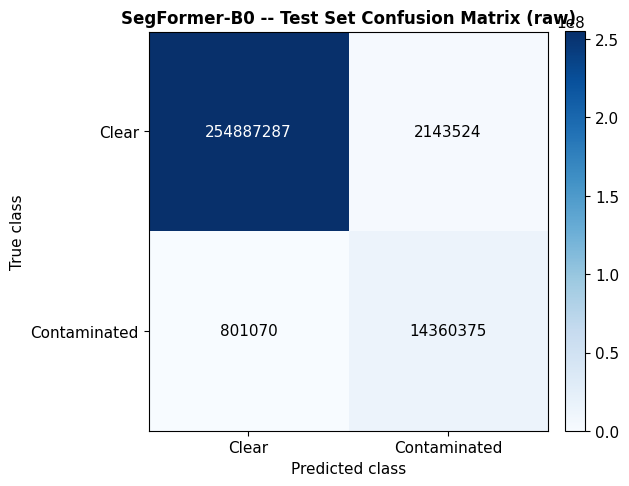

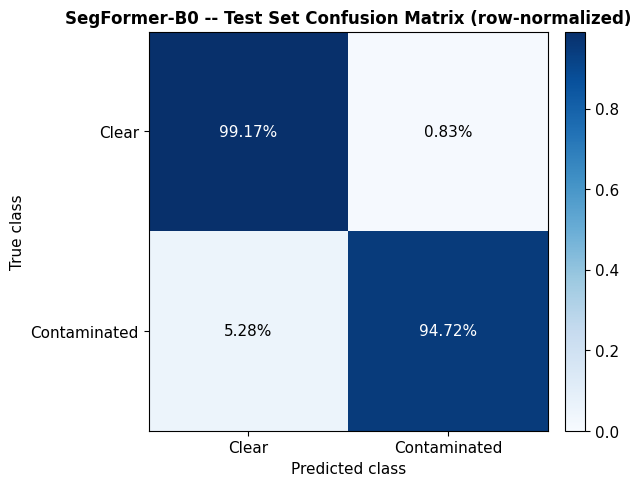

In [18]:
# ============================================================================
# PIXEL-LEVEL CONFUSION MATRIX (raw + normalized)
# ============================================================================
def normalize_confusion_matrix(cm: np.ndarray, epsilon: float = 1e-8) -> np.ndarray:
    """Row-normalize (recall-style) a confusion matrix."""
    return cm.astype(np.float64) / (cm.sum(axis=1, keepdims=True) + epsilon)


def plot_confusion_matrix(cm: np.ndarray, class_names: list, normalize: bool, title: str, save_path: Path) -> None:
    """Render and save a publication-quality confusion-matrix heatmap."""
    display_matrix = normalize_confusion_matrix(cm) if normalize else cm
    fmt = ".2%" if normalize else "d"

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(display_matrix, cmap="Blues", vmin=0)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names)
    ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title(title, fontweight="bold")

    threshold = display_matrix.max() / 2.0
    for i in range(display_matrix.shape[0]):
        for j in range(display_matrix.shape[1]):
            value = display_matrix[i, j]
            text = f"{value:{fmt}}" if normalize else f"{int(value)}"
            ax.text(j, i, text, ha="center", va="center",
                    color="white" if value > threshold else "black", fontsize=11)

    fig.tight_layout()
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


plot_confusion_matrix(
    test_confusion_matrix, CLASS_NAMES_BY_INDEX, normalize=False,
    title="SegFormer-B0 -- Test Set Confusion Matrix (raw)",
    save_path=FIGURES_DIR / "confusion_matrix.png",
)
plot_confusion_matrix(
    test_confusion_matrix, CLASS_NAMES_BY_INDEX, normalize=True,
    title="SegFormer-B0 -- Test Set Confusion Matrix (row-normalized)",
    save_path=FIGURES_DIR / "confusion_matrix_normalized.png",
)


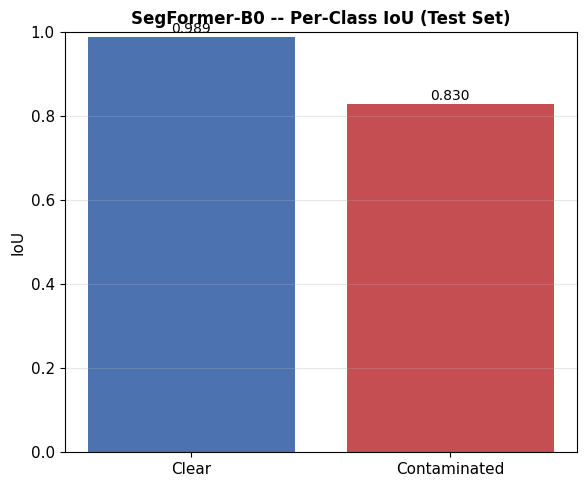

Saved -> segformer-result2-part2/results/segformer/figures/class_wise_iou.png


In [19]:
# ============================================================================
# CLASS-WISE IoU PLOT
# ============================================================================
fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(per_class_metrics_table["class"], per_class_metrics_table["iou"],
              color=["#4C72B0", "#C44E52"][:len(per_class_metrics_table)])
ax.set_ylabel("IoU"); ax.set_ylim(0, 1)
ax.set_title("SegFormer-B0 -- Per-Class IoU (Test Set)", fontweight="bold")
for bar, value in zip(bars, per_class_metrics_table["iou"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.3f}", ha="center", fontsize=10)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "class_wise_iou.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved -> {FIGURES_DIR / 'class_wise_iou.png'}")


---
# Section 11 — Visualization


In [20]:
# ============================================================================
# SHARED VISUALIZATION HELPER
# ============================================================================
def denormalize_image(image_tensor: torch.Tensor) -> np.ndarray:
    """Invert the Normalize step to recover a displayable uint8 RGB array."""
    mean = torch.tensor(NORMALIZATION_MEAN).view(3, 1, 1)
    std = torch.tensor(NORMALIZATION_STD).view(3, 1, 1)
    denorm = (image_tensor * std + mean).clamp(0, 1)
    return (denorm.permute(1, 2, 0).numpy() * 255).astype(np.uint8)


def get_sample_visualization_data(dataset: "KvasirSegmentationDataset", index: int, model: nn.Module, device: torch.device) -> dict[str, Any]:
    """Run inference on one dataset sample and return everything needed to
    visualize and quantify it.
    """
    sample = dataset[index]
    model.eval()
    with torch.no_grad():
        logits = extract_logits(model(sample["image"].unsqueeze(0).to(device)))
    prediction = decode_prediction(logits).squeeze(0).cpu()
    ground_truth = sample["mask"]

    cm = compute_confusion_matrix(prediction, ground_truth, NUM_CLASSES)
    metrics = compute_segmentation_metrics(cm)

    # Max-softmax confidence map (mean confidence across the predicted class)
    probs = F.softmax(logits, dim=1).squeeze(0).cpu()
    confidence_map = probs.max(dim=0).values.numpy()

    return {
        "image": denormalize_image(sample["image"]),
        "ground_truth": ground_truth.numpy(),
        "prediction": prediction.numpy(),
        "confidence": confidence_map,
        "filename": sample["image_filename"],
        "iou": metrics["mean_iou"], "dice": metrics["mean_dice"], "pixel_accuracy": metrics["pixel_accuracy"],
    }


def plot_prediction_grid(records: list, title: str, save_path: Path) -> None:
    """Plot Image | Ground Truth | Prediction | Overlay for each record, one
    row per sample, annotated with filename and per-image metrics.
    """
    n = len(records)
    fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
    if n == 1:
        axes = axes[None, :]
    col_titles = ["Original Image", "Ground Truth", "Predicted Mask", "Overlay (Prediction)"]

    for row, record in enumerate(records):
        overlay = overlay_mask(record["image"], record["prediction"])
        panels = [record["image"], record["ground_truth"], record["prediction"], overlay]
        cmaps = [None, "gray", "gray", None]
        for col, (panel, cmap) in enumerate(zip(panels, cmaps)):
            ax = axes[row, col]
            ax.imshow(panel, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
            if row == 0:
                ax.set_title(col_titles[col], fontsize=12)
            ax.axis("off")
        axes[row, 0].text(
            -0.05, 0.5,
            f"{record['filename']}\nIoU={record['iou']:.3f}  Dice={record['dice']:.3f}",
            transform=axes[row, 0].transAxes, fontsize=8, ha="right", va="center",
        )

    fig.suptitle(title, fontsize=14, y=1.0)
    fig.tight_layout()
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


print("Visualization helpers ready: get_sample_visualization_data, plot_prediction_grid")


Visualization helpers ready: get_sample_visualization_data, plot_prediction_grid


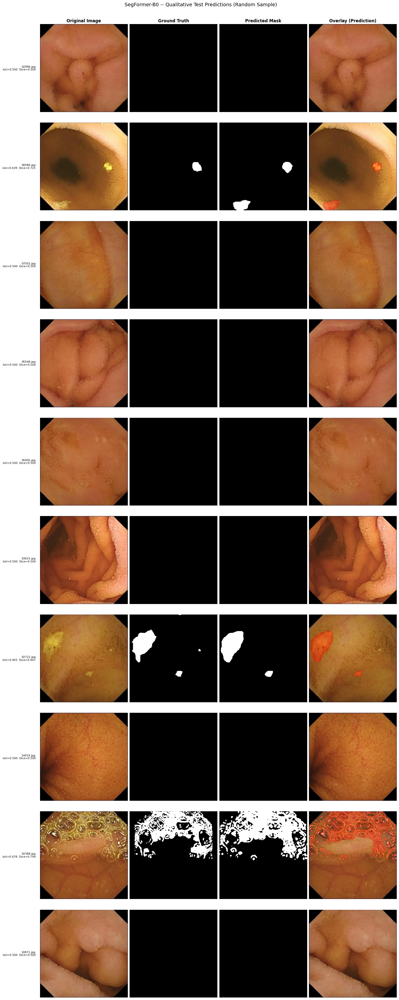

Saved -> segformer-result2-part2/results/segformer/figures/qualitative_predictions.png (10 samples)
Saved 10 prediction masks -> segformer-result2-part2/results/segformer/predictions


In [21]:
# ============================================================================
# QUALITATIVE PREDICTION VISUALIZATION -- 10 random test images
# ============================================================================
N_QUALITATIVE_SAMPLES = 10
_qualitative_indices = random.sample(range(len(test_dataset)), min(N_QUALITATIVE_SAMPLES, len(test_dataset)))
qualitative_records = [
    get_sample_visualization_data(test_dataset, idx, best_model, DEVICE) for idx in _qualitative_indices
]

plot_prediction_grid(
    qualitative_records, "SegFormer-B0 -- Qualitative Test Predictions (Random Sample)",
    FIGURES_DIR / "qualitative_predictions.png",
)
print(f"Saved -> {FIGURES_DIR / 'qualitative_predictions.png'} ({len(qualitative_records)} samples)")

# --- Save the predicted masks for these samples -----------------------------
for record in qualitative_records:
    stem = Path(record["filename"]).stem
    pred_uint8 = (record["prediction"] * 255).astype(np.uint8)
    cv2.imwrite(str(PREDICTIONS_DIR / f"{stem}_pred.png"), pred_uint8)
print(f"Saved {len(qualitative_records)} prediction masks -> {PREDICTIONS_DIR}")


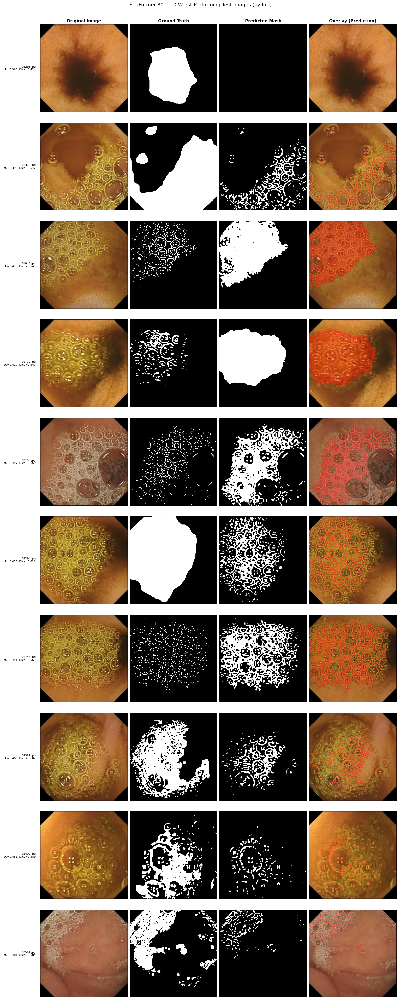

Saved -> segformer-result2-part2/results/segformer/figures/worst_performing_images.png


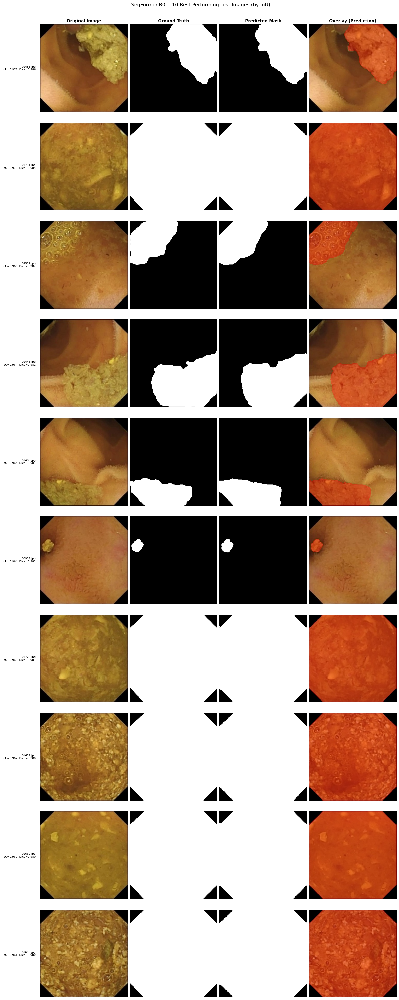

Saved -> segformer-result2-part2/results/segformer/figures/best_performing_images.png


In [22]:
# ============================================================================
# WORST- AND BEST-PERFORMING IMAGES (Task G error analysis)
# ============================================================================
N_ERROR_ANALYSIS_SAMPLES = 10

worst_10_df = per_image_metrics_df.sort_values("iou", ascending=True).head(N_ERROR_ANALYSIS_SAMPLES)
worst_10_records = [get_sample_visualization_data(test_dataset, idx, best_model, DEVICE) for idx in worst_10_df.index]
plot_prediction_grid(
    worst_10_records, "SegFormer-B0 -- 10 Worst-Performing Test Images (by IoU)",
    FIGURES_DIR / "worst_performing_images.png",
)
print(f"Saved -> {FIGURES_DIR / 'worst_performing_images.png'}")

best_10_df = per_image_metrics_df.sort_values("iou", ascending=False).head(N_ERROR_ANALYSIS_SAMPLES)
best_10_records = [get_sample_visualization_data(test_dataset, idx, best_model, DEVICE) for idx in best_10_df.index]
plot_prediction_grid(
    best_10_records, "SegFormer-B0 -- 10 Best-Performing Test Images (by IoU)",
    FIGURES_DIR / "best_performing_images.png",
)
print(f"Saved -> {FIGURES_DIR / 'best_performing_images.png'}")


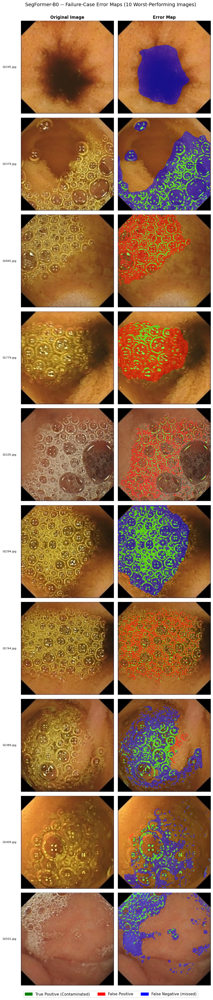

Saved -> segformer-result2-part2/results/segformer/figures/failure_case_error_maps.png


In [23]:
# ============================================================================
# ERROR MAPS -- False Positives / False Negatives / Correct Predictions
# (failure-case visualization, on the 10 worst-performing images)
# ============================================================================
def generate_error_map(image: np.ndarray, ground_truth: np.ndarray, prediction: np.ndarray, alpha: float = 0.5) -> np.ndarray:
    """Overlay a color-coded error map onto `image`: green = true positive,
    red = false positive, blue = false negative (missed contamination).
    """
    contaminated = FIXED_CLASS_MAPPING["Contaminated"]
    true_positive = (ground_truth == contaminated) & (prediction == contaminated)
    false_positive = (ground_truth != contaminated) & (prediction == contaminated)
    false_negative = (ground_truth == contaminated) & (prediction != contaminated)

    color_map = np.zeros_like(image)
    color_map[true_positive] = [0, 255, 0]
    color_map[false_positive] = [255, 0, 0]
    color_map[false_negative] = [0, 0, 255]

    highlighted = true_positive | false_positive | false_negative
    return np.where(highlighted[..., None], (image * (1 - alpha) + color_map * alpha).astype(np.uint8), image)


fig, axes = plt.subplots(N_ERROR_ANALYSIS_SAMPLES, 2, figsize=(9, 4 * N_ERROR_ANALYSIS_SAMPLES))
for row, record in enumerate(worst_10_records):
    error_map = generate_error_map(record["image"], record["ground_truth"], record["prediction"])
    axes[row, 0].imshow(record["image"]); axes[row, 0].set_title("Original Image" if row == 0 else ""); axes[row, 0].axis("off")
    axes[row, 1].imshow(error_map); axes[row, 1].set_title("Error Map" if row == 0 else ""); axes[row, 1].axis("off")
    axes[row, 0].text(-0.05, 0.5, record["filename"], transform=axes[row, 0].transAxes,
                       fontsize=8, ha="right", va="center")

legend_patches = [
    mpatches.Patch(color="green", label="True Positive (Contaminated)"),
    mpatches.Patch(color="red", label="False Positive"),
    mpatches.Patch(color="blue", label="False Negative (missed)"),
]
fig.legend(handles=legend_patches, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("SegFormer-B0 -- Failure-Case Error Maps (10 Worst-Performing Images)", fontsize=14, y=1.0)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "failure_case_error_maps.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved -> {FIGURES_DIR / 'failure_case_error_maps.png'}")


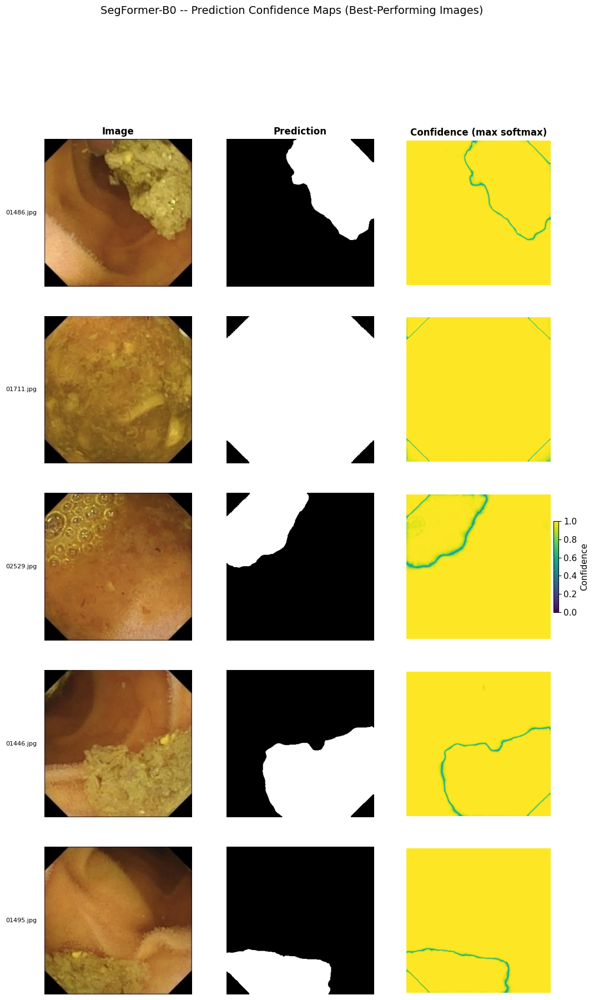

Saved -> segformer-result2-part2/results/segformer/figures/confidence_maps.png


In [24]:
# ============================================================================
# CONFIDENCE VISUALIZATION -- max-softmax confidence map, best-performing images
# ============================================================================
fig, axes = plt.subplots(min(5, len(best_10_records)), 3, figsize=(12, 4 * min(5, len(best_10_records))))
if min(5, len(best_10_records)) == 1:
    axes = axes[None, :]
for row, record in enumerate(best_10_records[:5]):
    axes[row, 0].imshow(record["image"]); axes[row, 0].set_title("Image" if row == 0 else ""); axes[row, 0].axis("off")
    axes[row, 1].imshow(record["prediction"], cmap="gray"); axes[row, 1].set_title("Prediction" if row == 0 else ""); axes[row, 1].axis("off")
    conf_im = axes[row, 2].imshow(record["confidence"], cmap="viridis", vmin=0, vmax=1)
    axes[row, 2].set_title("Confidence (max softmax)" if row == 0 else ""); axes[row, 2].axis("off")
    axes[row, 0].text(-0.05, 0.5, record["filename"], transform=axes[row, 0].transAxes,
                       fontsize=8, ha="right", va="center")
fig.colorbar(conf_im, ax=axes[:, 2].tolist(), fraction=0.03, pad=0.02, label="Confidence")
fig.suptitle("SegFormer-B0 -- Prediction Confidence Maps (Best-Performing Images)", fontsize=14, y=1.0)
fig.savefig(FIGURES_DIR / "confidence_maps.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved -> {FIGURES_DIR / 'confidence_maps.png'}")


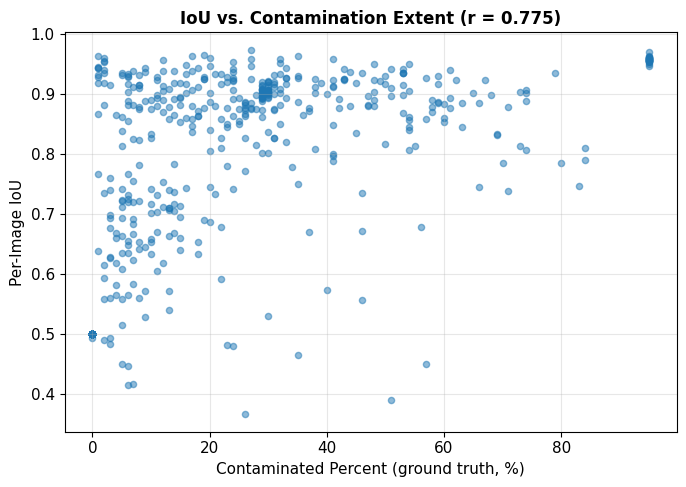

IoU vs. contamination-percent correlation : r = 0.775
Mean boundary-error fraction               : 0.5607456842706934
Mean segmentation ratio (pred/GT)            : 1.2952056605526645 (over-segmentation)


In [25]:
# ============================================================================
# FAILURE MODE ANALYSIS -- grounded in this run's actual numbers
# ============================================================================
_valid_corr = per_image_metrics_df.dropna(subset=["contaminated_percent", "iou"])
iou_contam_correlation = float(np.corrcoef(_valid_corr["contaminated_percent"], _valid_corr["iou"])[0, 1]) if len(_valid_corr) > 1 else float("nan")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(per_image_metrics_df["contaminated_percent"], per_image_metrics_df["iou"], alpha=0.5, s=20)
ax.set_xlabel("Contaminated Percent (ground truth, %)")
ax.set_ylabel("Per-Image IoU")
ax.set_title(f"IoU vs. Contamination Extent (r = {iou_contam_correlation:.3f})", fontweight="bold")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "iou_vs_contamination_percent.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

_boundary_fracs = per_image_metrics_df["boundary_error_fraction"].dropna()
mean_boundary_error_fraction = float(_boundary_fracs.mean()) if len(_boundary_fracs) > 0 else None

_valid_ratios = per_image_metrics_df["segmentation_ratio"].dropna()
mean_segmentation_ratio = float(_valid_ratios.mean()) if len(_valid_ratios) > 0 else None
segmentation_tendency = (
    "over-segmentation" if mean_segmentation_ratio and mean_segmentation_ratio > 1.05 else
    "under-segmentation" if mean_segmentation_ratio and mean_segmentation_ratio < 0.95 else
    "roughly balanced segmentation" if mean_segmentation_ratio else "undetermined (no GT-contaminated test images)"
)

print(f"IoU vs. contamination-percent correlation : r = {iou_contam_correlation:.3f}")
print(f"Mean boundary-error fraction               : {mean_boundary_error_fraction}")
print(f"Mean segmentation ratio (pred/GT)            : {mean_segmentation_ratio} ({segmentation_tendency})")


---
# Section 12 — Metrics Export


In [26]:
# ============================================================================
# METRICS EXPORT -- CSV + JSON
# ============================================================================
# --- test_metrics.csv (per-class + overall, one flat table) ----------------
_export_rows = per_class_metrics_table.to_dict(orient="records")
_export_rows.append({
    "class": "OVERALL", "iou": test_metrics["mean_iou"], "dice": test_metrics["mean_dice"],
    "precision": None, "recall": None, "f1": None,
    "pixel_accuracy": test_metrics["overall_pixel_accuracy"],
})
test_metrics_csv_path = TABLES_DIR / "test_metrics.csv"
pd.DataFrame(_export_rows).to_csv(test_metrics_csv_path, index=False)
print(f"Saved -> {test_metrics_csv_path}")

# --- per_image_metrics.csv --------------------------------------------------
per_image_metrics_csv_path = TABLES_DIR / "per_image_metrics.csv"
per_image_metrics_df.to_csv(per_image_metrics_csv_path, index=False)
print(f"Saved -> {per_image_metrics_csv_path}")

# --- metrics.json (fixed schema) --------------------------------------------
metrics_json = {
    "model_name": TRAINING_CONFIG["model_name"],
    "backbone": TRAINING_CONFIG["backbone"],
    "epochs": epochs_completed,
    "best_epoch": best_model_summary["best_epoch"],
    "mIoU": test_metrics["mean_iou"],
    "Dice": test_metrics["mean_dice"],
    "Overall Pixel Accuracy": test_metrics["overall_pixel_accuracy"],
    "Mean Pixel Accuracy": test_metrics["mean_pixel_accuracy"],
    "Per-class IoU": {name: stats["iou"] for name, stats in test_metrics["per_class"].items()},
    "Per-class Dice": {name: stats["dice"] for name, stats in test_metrics["per_class"].items()},
    "Inference Time": inference_timing["total_inference_time_seconds"],
    "FPS": inference_timing["fps"],
    "Training Time": best_model_summary.get("training_time_seconds"),
}
METRICS_JSON_PATH = OUTPUT_DIR / "metrics.json"
with open(METRICS_JSON_PATH, "w") as f:
    json.dump(metrics_json, f, indent=2, default=str)
print(f"Saved -> {METRICS_JSON_PATH}")

# --- results.json -- identical schema/content to metrics.json --------------
RESULTS_JSON_PATH = OUTPUT_DIR / "results.json"
with open(RESULTS_JSON_PATH, "w") as f:
    json.dump(metrics_json, f, indent=2, default=str)
print(f"Saved -> {RESULTS_JSON_PATH}")


Saved -> segformer-result2-part2/results/segformer/tables/test_metrics.csv
Saved -> segformer-result2-part2/results/segformer/tables/per_image_metrics.csv
Saved -> segformer-result2-part2/results/segformer/metrics.json
Saved -> segformer-result2-part2/results/segformer/results.json


---
# Section 13 — Reports


In [27]:
# ============================================================================
# MARKDOWN EVALUATION REPORT
# ============================================================================
_contaminated_iou = test_metrics["per_class"]["Contaminated"]["iou"]
_clear_iou = test_metrics["per_class"]["Clear"]["iou"]
_contaminated_recall = test_metrics["per_class"]["Contaminated"]["recall"]
_contaminated_precision = test_metrics["per_class"]["Contaminated"]["precision"]

evaluation_report_markdown = f"""# SegFormer-B0 -- Post-Training Evaluation Report (Part 2)

*Generated by `SegFormer_Part2.ipynb`, continuing from the completed
training run's checkpoint (`{BEST_CHECKPOINT_PATH.name}`, epoch
{best_model_summary['best_epoch']}). No training occurred in this notebook.*

## Test-Set Quantitative Results

| Metric | Value |
|---|---|
| Mean IoU | {test_metrics['mean_iou']:.4f} |
| Mean Dice | {test_metrics['mean_dice']:.4f} |
| Overall Pixel Accuracy | {test_metrics['overall_pixel_accuracy']:.4f} |
| Mean Pixel Accuracy | {test_metrics['mean_pixel_accuracy']:.4f} |
| Clear IoU | {_clear_iou:.4f} |
| Contaminated IoU | {_contaminated_iou:.4f} |
| Contaminated Precision | {_contaminated_precision:.4f} |
| Contaminated Recall | {_contaminated_recall:.4f} |
| Inference Throughput | {inference_timing['fps']:.2f} images/sec |

## Error Analysis Summary

- IoU vs. ground-truth contamination-percent correlation: r = {iou_contam_correlation:.3f}
- Mean boundary-error fraction: {f'{mean_boundary_error_fraction:.1%}' if mean_boundary_error_fraction is not None else 'N/A'}
  of misclassified pixels fall within a narrow band around the ground-truth boundary.
- Segmentation tendency: {segmentation_tendency} (mean predicted/GT contaminated-pixel ratio = {mean_segmentation_ratio if mean_segmentation_ratio else 'N/A'}).

## Artifacts

All figures, tables, predictions, and JSON/CSV metrics referenced above are
saved under `{OUTPUT_DIR}`.
"""

EVALUATION_REPORT_PATH = REPORTS_DIR / "Evaluation_Report.md"
EVALUATION_REPORT_PATH.write_text(evaluation_report_markdown)
display(Markdown(evaluation_report_markdown))
print(f"\nSaved -> {EVALUATION_REPORT_PATH}")


# SegFormer-B0 -- Post-Training Evaluation Report (Part 2)

*Generated by `SegFormer_Part2.ipynb`, continuing from the completed
training run's checkpoint (`best_model.pth`, epoch
42). No training occurred in this notebook.*

## Test-Set Quantitative Results

| Metric | Value |
|---|---|
| Mean IoU | 0.9092 |
| Mean Dice | 0.9506 |
| Overall Pixel Accuracy | 0.9892 |
| Mean Pixel Accuracy | 0.9694 |
| Clear IoU | 0.9886 |
| Contaminated IoU | 0.8298 |
| Contaminated Precision | 0.8701 |
| Contaminated Recall | 0.9472 |
| Inference Throughput | 231.58 images/sec |

## Error Analysis Summary

- IoU vs. ground-truth contamination-percent correlation: r = 0.775
- Mean boundary-error fraction: 56.1%
  of misclassified pixels fall within a narrow band around the ground-truth boundary.
- Segmentation tendency: over-segmentation (mean predicted/GT contaminated-pixel ratio = 1.2952056605526645).

## Artifacts

All figures, tables, predictions, and JSON/CSV metrics referenced above are
saved under `segformer-result2-part2/results/segformer`.



Saved -> segformer-result2-part2/results/segformer/reports/Evaluation_Report.md


In [28]:
# ============================================================================
# FINAL SUMMARY REPORT (plain text, mirrors the original notebook's style)
# ============================================================================
final_summary_lines = [
    "=" * 78, "SEGFORMER-B0 -- PART 2 (POST-TRAINING) FINAL SUMMARY", "=" * 78, "",
    f"Previous output directory (untouched)  : {PREVIOUS_OUTPUT_ROOT}",
    f"New output directory (this notebook)   : {NEW_OUTPUT_ROOT.resolve()}",
    f"Checkpoint used                         : {BEST_CHECKPOINT_PATH.name} (epoch {best_model_summary['best_epoch']})",
    "",
    f"Test mIoU                                 : {test_metrics['mean_iou']:.4f}",
    f"Test Dice                                  : {test_metrics['mean_dice']:.4f}",
    f"Test Overall Pixel Accuracy                  : {test_metrics['overall_pixel_accuracy']:.4f}",
    f"Test Mean Pixel Accuracy                       : {test_metrics['mean_pixel_accuracy']:.4f}",
    f"Inference Throughput                             : {inference_timing['fps']:.2f} images/sec",
    "",
    "No training occurred in this notebook. All checkpoints, configs, logs, "
    "and reports from the original run were copied unmodified into the new "
    "output directory before any new evaluation artifact was written.",
    "", "=" * 78,
]
FINAL_SUMMARY_PATH = REPORTS_DIR / "Part2_Final_Summary.txt"
FINAL_SUMMARY_PATH.write_text("\n".join(final_summary_lines))
print("\n".join(final_summary_lines))
print(f"\nSaved -> {FINAL_SUMMARY_PATH}")


SEGFORMER-B0 -- PART 2 (POST-TRAINING) FINAL SUMMARY

Previous output directory (untouched)  : /kaggle/input/datasets/bushratahsin/segformer-result2
New output directory (this notebook)   : /kaggle/working/segformer-result2-part2
Checkpoint used                         : best_model.pth (epoch 42)

Test mIoU                                 : 0.9092
Test Dice                                  : 0.9506
Test Overall Pixel Accuracy                  : 0.9892
Test Mean Pixel Accuracy                       : 0.9694
Inference Throughput                             : 231.58 images/sec

No training occurred in this notebook. All checkpoints, configs, logs, and reports from the original run were copied unmodified into the new output directory before any new evaluation artifact was written.


Saved -> segformer-result2-part2/results/segformer/reports/Part2_Final_Summary.txt


---
# Section 14 — Export Results & Notebook Metadata


In [29]:
# ============================================================================
# NOTEBOOK METADATA (Output Structure)
# ============================================================================
notebook_metadata = {
    "notebook_name": "SegFormer_Part2.ipynb",
    "model_name": TRAINING_CONFIG["model_name"],
    "role": "Post-training continuation: evaluation, error analysis, reporting only -- no training.",
    "previous_output_root": str(PREVIOUS_OUTPUT_ROOT),
    "new_output_root": str(NEW_OUTPUT_ROOT.resolve()),
    "checkpoint_used": str(BEST_CHECKPOINT_PATH),
    "checkpoint_epoch": best_model_summary["best_epoch"],
    "sections_completed": [
        "1. Import Libraries", "2. Locate Previous Output Directory",
        "3. Create New Output Directory", "4. Copy Previous Outputs",
        "5. Load Preprocessing Outputs & Training Configuration",
        "6. Rebuild SegFormer Model, Transforms & Dataset",
        "7. Rebuild Model & Load Best Checkpoint",
        "8. Metrics Module & Load Test Dataset",
        "9. Inference & Final Validation (Optional)",
        "10. Task F -- Testing & Quantitative Evaluation",
        "11. Visualization", "12. Metrics Export", "13. Reports",
        "14. Export Results & Notebook Metadata",
    ],
    "execution_date": datetime.now().isoformat(timespec="seconds"),
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "transformers_version": transformers.__version__,
    "random_seed": RANDOM_SEED,
    "device_used": str(DEVICE),
}
NOTEBOOK_METADATA_PATH = OUTPUT_DIR / "notebook_metadata_part2.json"
with open(NOTEBOOK_METADATA_PATH, "w") as f:
    json.dump(notebook_metadata, f, indent=2, default=str)
print(f"Saved -> {NOTEBOOK_METADATA_PATH}")

print("\nFinal contents of the new output directory:")
for p in sorted(NEW_OUTPUT_ROOT.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(NEW_OUTPUT_ROOT)}")


Saved -> segformer-result2-part2/results/segformer/notebook_metadata_part2.json

Final contents of the new output directory:
  __huggingface_repos__.json
  __results___files/__results___14_0.png
  __results___files/__results___40_0.png
  __results___files/__results___40_1.png
  __results___files/__results___40_2.png
  __results___files/__results___40_3.png
  __results___files/__results___40_4.png
  results/segformer/checkpoints/best_model.pth
  results/segformer/checkpoints/best_model_epoch001_miou0.8428.pth
  results/segformer/checkpoints/best_model_epoch002_miou0.8634.pth
  results/segformer/checkpoints/best_model_epoch004_miou0.8679.pth
  results/segformer/checkpoints/best_model_epoch005_miou0.8803.pth
  results/segformer/checkpoints/best_model_epoch007_miou0.8878.pth
  results/segformer/checkpoints/best_model_epoch010_miou0.9033.pth
  results/segformer/checkpoints/best_model_epoch038_miou0.9055.pth
  results/segformer/checkpoints/best_model_epoch042_miou0.9057.pth
  results/segform

In [30]:
# ============================================================================
# FINAL VALIDATION CHECKS
# ============================================================================
final_checks: list = []

def _check(label: str, condition: bool, detail: str = "") -> None:
    final_checks.append({"check": label, "passed": bool(condition), "detail": detail})

_check("No new epochs were executed (training loop absent by construction)", True)
_check("Previous output directory untouched", PREVIOUS_CHECKPOINTS_DIR.is_dir())
_check("New output directory created", NEW_OUTPUT_ROOT.is_dir())
_check("Previous outputs copied into new directory", n_copied >= 0)
_check("Best checkpoint loaded", best_model is not None)
_check("Test-set evaluation completed", "mean_iou" in test_metrics)
_check("Metrics exported (metrics.json + results.json)", METRICS_JSON_PATH.is_file() and RESULTS_JSON_PATH.is_file())
_check("Evaluation report exported", EVALUATION_REPORT_PATH.is_file())
_check("Notebook metadata exported", NOTEBOOK_METADATA_PATH.is_file())

final_checks_df = pd.DataFrame(final_checks)
display(final_checks_df)

n_failed = int((~final_checks_df["passed"]).sum())
print(f"\n{len(final_checks_df) - n_failed}/{len(final_checks_df)} checks passed.")
if n_failed > 0:
    raise RuntimeError(f"{n_failed} check(s) failed -- see the table above.")

display(Markdown(
    "**SegFormer-B0 Part 2 complete.** All post-training tasks (test-set "
    "evaluation, error analysis, visualizations, metrics export, and "
    "reporting) were run against the checkpoint from the completed training "
    "run, with every previous artifact preserved and all new outputs written "
    f"to `{NEW_OUTPUT_ROOT.resolve()}`."
))


,check,passed,detail
0,No new epochs were executed (training loop abs...,True,
1,Previous output directory untouched,True,
2,New output directory created,True,
3,Previous outputs copied into new directory,True,
4,Best checkpoint loaded,True,
5,Test-set evaluation completed,True,
6,Metrics exported (metrics.json + results.json),True,
7,Evaluation report exported,True,
8,Notebook metadata exported,True,



9/9 checks passed.


**SegFormer-B0 Part 2 complete.** All post-training tasks (test-set evaluation, error analysis, visualizations, metrics export, and reporting) were run against the checkpoint from the completed training run, with every previous artifact preserved and all new outputs written to `/kaggle/working/segformer-result2-part2`.